# All 12,860 driver-weeks, with the definition lines and gaming: what do the city totals say, and which drivers and zones drive the fall?

**Week 4, Monday, chapter 8 of 11, the second case chapter.** It applies two of the morning's
topics: *Definitions: numerator, denominator, window, exclusions*, taught in
`C2_W04_D01_04_numerator_denominator_window_exclusions_STUDENT.ipynb`, and *Gaming, and
definitions that resist it*, taught in `C2_W04_D01_05_gaming_resistant_definitions_STUDENT.ipynb`.
Levels 2 and 3 of the case's six: the same count on the full data in the smallest code, then the
trap, the denominator and the segment that drives the number. New in the setup cell:
`.lt("2026-08-31")` asks whether each week starts before the launch, and `.map` turns True and
False into before and after.

**The case.** Uber's Hyderabad city team launched a peak-hour earnings guarantee on Monday
31 August 2026, a floor of Rs 300 per peak online hour with Uber paying the gap as a top-up.
Peak online hours rose 24 percent over the six weeks after the launch, completed peak trips 3
percent, and the city head asks whether the scheme is working, what it should pay for and
whether anyone is gaming it.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

Notebook 07 counted six drivers by hand: their hours rose from 60 to 74, their trips fell from
114 to 88, and trips per peak online hour fell from 1.90 to 1.19, pulled down by two drivers in
outer zones. This notebook runs the count on every driver-week.

**Who needs the answer.** The city head, before a proposal to extend the scheme to two more
cities goes out. A fall read as weak demand, or measured with the wrong denominator, sends the
same top-up further.

**The questions on the way.**

1. What are the city's totals before and after the launch?
2. Did rider demand fall?
3. What does a quick average of each driver-week's rate say, and why is it wrong?
4. Which drivers sit under 1.0 trip per peak online hour after the launch?
5. Where did their new hours go, and does a second route find the same drivers?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zw = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
dw["window"] = dw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
zw["window"] = zw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
print(f"{len(dw):,} driver-weeks and {len(zw)} zone-weeks, twelve weeks from {dw.week_start.min()}")

12,860 driver-weeks and 144 zone-weeks, twelve weeks from 2026-07-20


## What are the city's totals before and after the launch?

A rate is a ratio of two sums: add up every trip, add up every hour, then divide. Its four lines,
as chapter 4 writes them: numerator, completed peak trips; denominator, peak online hours;
window, the six weeks on each side of the launch; exclusions, none. This cell sums the six weeks
on each side of the launch and takes each rate that way.

In [2]:
city = dw.groupby("window")[["peak_online_hours", "peak_trips", "peak_offers", "peak_accepted",
                             "peak_driver_cancels", "peak_hours_no_trip"]].sum().loc[["before", "after"]]
city["trips_per_hour"] = (city["peak_trips"] / city["peak_online_hours"]).round(2)
city["acceptance"] = (city["peak_accepted"] / city["peak_offers"]).round(3)
city["driver_cancel_share"] = (city["peak_driver_cancels"] / city["peak_accepted"]).round(3)
city["no_trip_share"] = (city["peak_hours_no_trip"] / city["peak_online_hours"]).round(2)
city.T

window,before,after
peak_online_hours,118000.000,146300.00
peak_trips,224200.000,230900.00
peak_offers,269773.000,347583.00
peak_accepted,232814.000,253736.00
peak_driver_cancels,8614.000,22836.00
peak_hours_no_trip,25960.000,55614.00
trips_per_hour,1.900,1.58
acceptance,0.863,0.73
driver_cancel_share,0.037,0.09
no_trip_share,0.220,0.38


**What happened.** Peak online hours rose from 118,000 to 146,300 and completed peak trips from
224,200 to 230,900, so trips per peak online hour fell from 1.90 to 1.58. The share of offers
accepted fell from 0.863 to 0.730, the share of accepted trips the driver then cancelled rose
from 0.037 to 0.090, and the share of online hours with no completed trip rose from 0.22 to
0.38.

## Did rider demand fall?

If riders asked for fewer trips, trips per online hour would fall with nobody gaming
anything. Demand lives in `zone_weeks`, which counts rider requests.

**Predict before you run.** From the six weeks before to the six weeks after, rider requests
a) fell by about a tenth; b) held about level; c) rose a little; d) rose by a quarter, as
hours did.

This cell sums requests and fulfilled requests by window, takes the city's wait as the median
of the 72 zone-week median waits in each window (12 zones for six weeks), and sets offers
beside requests. New in it: `.agg(name=(column, "sum"))` makes several named totals in one
step.

In [3]:
demand = zw.groupby("window").agg(requests=("peak_requests", "sum"), fulfilled=("peak_fulfilled", "sum"),
                                  median_wait=("median_wait_min", "median")).loc[["before", "after"]]
demand["unfulfilled_share"] = (1 - demand["fulfilled"] / demand["requests"]).round(2)
demand["offers_per_request"] = (city["peak_offers"] / demand["requests"]).round(2)
demand

,requests,fulfilled,median_wait,unfulfilled_share,offers_per_request
window,,,,,
before,251910,224200,4.8,0.11,1.07
after,256556,230900,4.6,0.10,1.35


**What happened.** The answer is c: rider requests rose from 251,910 to 256,556, up 1.8
percent, and the share left unfulfilled went from 0.11 to 0.10, while the median wait moved
from 4.8 to 4.6 minutes. The fall is not demand. Offers per request rose from 1.07 to 1.35,
because a request that one driver declines is offered to the next and counted again in
`driver_weeks`: more declining shows up as more offers for the same riders. Offers and requests
are two units for one crowd, as chapter 4's Delhi Metro counted riders once and line uses
again.

This cell draws the twelve weeks, hours on the left axis and trips per hour on the right
(`ax.twinx()` adds the second axis), to
see whether the after window is two odd weeks or a level that held.

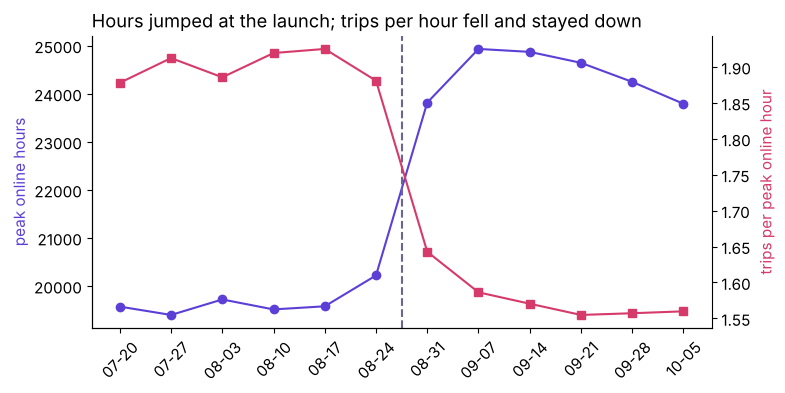

week_start,2026-07-20,2026-07-27,2026-08-03,2026-08-10,2026-08-17,2026-08-24,2026-08-31,2026-09-07,2026-09-14,2026-09-21,2026-09-28,2026-10-05
trips_per_hour,1.88,1.91,1.89,1.92,1.93,1.88,1.64,1.59,1.57,1.55,1.56,1.56


In [4]:
weekly = dw.groupby("week_start")[["peak_online_hours", "peak_trips"]].sum()
weekly["trips_per_hour"] = weekly["peak_trips"] / weekly["peak_online_hours"]
fig, ax = plt.subplots(figsize=(8.0, 3.8))
ax.plot(range(12), weekly["peak_online_hours"], marker="o", color=VIOLET)
ax.set_ylabel("peak online hours", color=VIOLET)
right = ax.twinx()
right.plot(range(12), weekly["trips_per_hour"], marker="s", color=ROSE)
right.set_ylabel("trips per peak online hour", color=ROSE)
right.spines["right"].set_visible(True)
ax.axvline(5.5, color=MUTED, linestyle="--")
ax.set_xticks(range(12), [w[5:] for w in weekly.index], rotation=45)
ax.set_title("Hours jumped at the launch; trips per hour fell and stayed down", loc="left")
plt.show()
weekly["trips_per_hour"].round(2).to_frame().T

**What happened.** Before the launch, trips per hour wandered between 1.88 and 1.93. In the
launch week it read 1.64, and from then on it stayed between 1.55 and 1.59. Hours rose from
about 20,000 a week to about 24,000. The fall held for six weeks.

## What does a quick average of each driver-week's rate say?

**The plausible wrong answer.** A colleague in a hurry works out trips per hour for each
driver-week, then takes the plain average of those rates for each window.

**Predict before you run.** What does that average print for the after window? a) 1.58;
b) 1.71; c) 1.19; d) 1.90.

This cell computes the colleague's number beside the ratio of the sums.

In [5]:
online = dw[dw["peak_online_hours"] > 0].copy()
online["rate"] = online["peak_trips"] / online["peak_online_hours"]
compare = pd.DataFrame({"mean_of_rates": online.groupby("window")["rate"].mean().round(2),
                        "ratio_of_sums": city["trips_per_hour"]}).loc[["before", "after"]]
compare

,mean_of_rates,ratio_of_sums
window,,
before,1.90,1.90
after,1.71,1.58


**Why it is wrong.** The answer is b: the average of rates prints 1.71, against 1.58 from the
sums. The true fall is 0.32, from 1.90 to 1.58; the average shows 0.19 of it and hides 0.13,
about two-fifths. An average of rates gives a 42-hour driver-week the same weight as a 10-hour
one, so the long, slow weeks of the drivers online longest count no more than anyone's short,
busy ones. With **invented numbers**: a driver at 2.0 trips an hour for 10 hours (20 trips)
and a driver at 0.5 for 40 hours (20 trips) made 40 trips in 50 hours, which is 0.80 an hour,
while the average of their two rates is 1.25: too high, in the same direction as the city's
1.71. The fix is the ratio of the sums, with its denominator named: trips per peak online
hour, all hours in the window.

## Which drivers sit under 1.0 trip per peak online hour after the launch?

**Predict before you run.** Of the 1,200 drivers, how many made fewer than one trip per peak
online hour across the six weeks after the launch? a) about 30; b) about 100; c) about 180;
d) about 400.

**Your turn.** Type these lines into the empty cell below and run it:

```python
after = dw[dw["window"] == "after"]
per_driver = after.groupby("driver_id")[["peak_trips", "peak_online_hours"]].sum()
per_driver["rate"] = per_driver["peak_trips"] / per_driver["peak_online_hours"]
(per_driver["rate"] < 1.0).sum()
```

Your cell prints a count of drivers. The next cell builds the same group so the rest of the
notebook can use it, and sets their hours and trips before and after; `:.0%` prints a share as
a whole percent.

In [6]:
after = dw[dw["window"] == "after"]
per_driver = after.groupby("driver_id")[["peak_trips", "peak_online_hours"]].sum()
slow = set(per_driver.index[per_driver["peak_trips"] / per_driver["peak_online_hours"] < 1.0])
tail = dw[dw["driver_id"].isin(slow)].groupby("window")[["peak_online_hours", "peak_trips"]].sum()
tail = tail.loc[["before", "after"]]
print(f"{len(slow)} drivers, {len(slow) / 1200:.0%} of the 1,200")
print("hours, after over before:", round(tail.loc["after", "peak_online_hours"] / tail.loc["before", "peak_online_hours"], 2))
print("trips, after over before:", round(tail.loc["after", "peak_trips"] / tail.loc["before", "peak_trips"], 2))

180 drivers, 15% of the 1,200
hours, after over before: 2.1
trips, after over before: 0.88


**What happened.** The answer is c: 180 drivers, 15 percent of the 1,200. Their peak online
hours after the launch were 2.1 times their hours before, while their trips were 0.88 times,
down 12 percent. Call them the **idle tail**: drivers who stayed online without driving. It is
chapter 5's first way of gaming, the paid person controlling the count, since a driver decides
when the app is open. The six of chapter 7 held two such drivers, a third of the sample against
15 percent city-wide, which is why the six fell to 1.19 while the city fell to 1.58.

## Where did the idle tail's new hours go?

This cell compares the idle tail's hours in the three outer zones before and after, then
draws every driver-week after the launch, hours against trips.

new hours 22,000; share logged in the outer zones 0.72


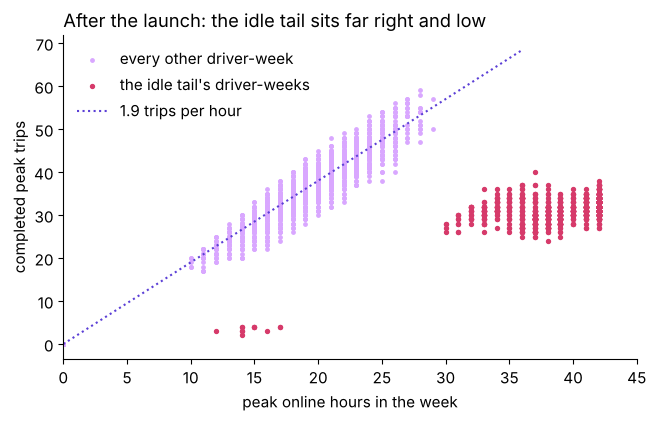

In [7]:
OUTER = ["Shamshabad", "Rajendranagar", "Patancheru"]
idle = dw[dw["driver_id"].isin(slow)]
outer_hours = idle[idle["zone_mode"].isin(OUTER)].groupby("window")["peak_online_hours"].sum()
new_hours = tail.loc["after", "peak_online_hours"] - tail.loc["before", "peak_online_hours"]
outer_share = (outer_hours["after"] - outer_hours["before"]) / new_hours
print(f"new hours {new_hours:,}; share logged in the outer zones {outer_share:.2f}")
mark = after["driver_id"].isin(slow)
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.scatter(after.loc[~mark, "peak_online_hours"], after.loc[~mark, "peak_trips"], s=6, color=LAV,
           label="every other driver-week")
ax.scatter(after.loc[mark, "peak_online_hours"], after.loc[mark, "peak_trips"], s=8, color=ROSE,
           label="the idle tail's driver-weeks")
ax.plot([0, 36], [0, 36 * 1.9], linestyle=":", color=VIOLET, label="1.9 trips per hour")
ax.set_xlim(0, 45)
ax.set_xlabel("peak online hours in the week")
ax.set_ylabel("completed peak trips")
ax.set_title("After the launch: the idle tail sits far right and low", loc="left")
ax.legend(frameon=False)
plt.show()

**What happened.** The idle tail logged 22,000 new hours, and 72 percent of them sat in the
three outer zones, where requests are thin at any hour: a driver parked there stays online,
is shown few requests, and is paid the floor. A week holds at most 42 peak hours (two
three-hour windows a day, seven days), and many idle-tail weeks sit near that edge.

## Does a second route find the same drivers?

The first route sorted drivers by trips per hour. The second ignores trips and asks only how
often each driver accepted what the app offered: this cell keeps every driver whose accepted
share stayed under 0.5 in every week they worked after the launch, then draws requests by
zone to show how thin the outer zones are.

180 drivers by acceptance; the same drivers as the first route: True


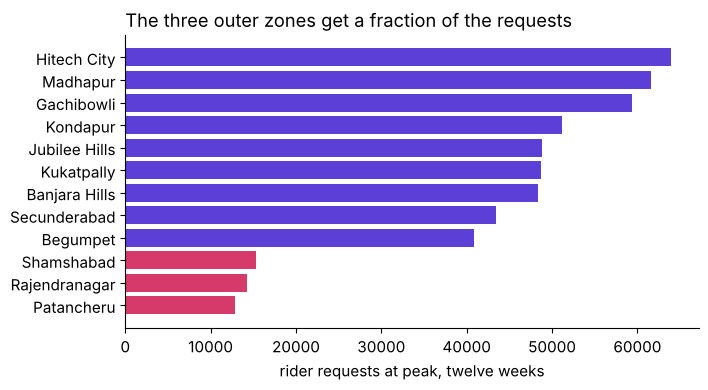

In [8]:
weeks_after = after[after["peak_offers"] > 0]
low_every_week = (weeks_after["peak_accepted"] / weeks_after["peak_offers"] < 0.5).groupby(weeks_after["driver_id"]).all()
second = set(low_every_week.index[low_every_week])
print(f"{len(second)} drivers by acceptance; the same drivers as the first route: {second == slow}")
by_zone = zw.groupby("zone")["peak_requests"].sum().sort_values()
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.barh(by_zone.index, by_zone.values, color=[ROSE if z in OUTER else VIOLET for z in by_zone.index])
ax.set_xlabel("rider requests at peak, twelve weeks")
ax.set_title("The three outer zones get a fraction of the requests", loc="left")
plt.show()

In [9]:
check("hours 118,000 before and 146,300 after", list(city["peak_online_hours"]) == [118000, 146300])
check("trips per peak online hour 1.90 before and 1.58 after", list(city["trips_per_hour"]) == [1.90, 1.58])
check("rider requests rose, 251,910 to 256,556", list(demand["requests"]) == [251910, 256556])
check("the average of rates prints 1.71 after, above the true 1.58", compare.loc["after", "mean_of_rates"] == 1.71)
check("180 drivers under 1.0 trip per hour after the launch", len(slow) == 180)
check("the idle tail's hours 2.1 times, trips 0.88 times",
      round(tail.loc["after", "peak_online_hours"] / tail.loc["before", "peak_online_hours"], 2) == 2.1
      and round(tail.loc["after", "peak_trips"] / tail.loc["before", "peak_trips"], 2) == 0.88)
check("72 percent of the new hours in the outer zones", round(outer_share, 2) == 0.72)
check("the acceptance route finds the same 180 drivers", second == slow)

PASS hours 118,000 before and 146,300 after
PASS trips per peak online hour 1.90 before and 1.58 after
PASS rider requests rose, 251,910 to 256,556
PASS the average of rates prints 1.71 after, above the true 1.58
PASS 180 drivers under 1.0 trip per hour after the launch
PASS the idle tail's hours 2.1 times, trips 0.88 times
PASS 72 percent of the new hours in the outer zones
PASS the acceptance route finds the same 180 drivers


## What does chapter 8 answer?

1. Hours rose from 118,000 to 146,300 and trips from 224,200 to 230,900: 1.90 to 1.58 trips an hour.
2. Demand did not fall: rider requests rose 1.8 percent, and waits moved from 4.8 to 4.6 minutes.
3. An average of each week's rate prints 1.71 and hides two-fifths of the fall; the ratio of
   the sums, 1.58, is the number.
4. 180 drivers, 15 percent, sit under 1.0 trip an hour after the launch, with hours 2.1 times
   and trips 0.88 times their level before.
5. 72 percent of their new hours sat in the three thin outer zones, and the acceptance route
   finds the same 180 drivers.

**The check a senior analyst runs.** Before celebrating hours, set the baseline (1.90) beside
the new rate (1.58), name the denominator (hours the app was open), look for the evidence in
a second table (rider requests rose), and reach the segment a second way (acceptance finds
the same 180).

**In the interview.** [F] What makes a metric gameable? The measured person controls the
count: here a driver decides when the app is open. Notebook 09 prices what that cost and
writes the number the scheme should pay for.